# 11 · A threshold rule that reads calibrated probabilities

This notebook reports two tagging methods, `jev-statement-code-platt` and
`jev-statement-code-gepa-platt`: the calibrated twins of `jev-statement-code` and of
`jev-statement-code-gepa`. A twin reads its base's committed answers, so it sends no request and
costs nothing, and its probabilities are its base's. It changes one thing: its threshold rule,
the way a tag's probability becomes 0/1.

**Contents**
1. Setup and checks
2. Are Jev's probabilities calibrated?
3. Why the F1-argmax threshold moves
4. The declared comparison and the nested choice
5. Each twin against its base on dev
6. The test set, reported once
7. Takeaways and next steps

**How it was built** ([ADR 0011](../docs/adr/0011-platt-lipton-threshold-rule.md))
- **The rule of the frozen methods (R0)** takes, per tag, the threshold where the F1 of the
  fitting scores is highest. When the F1 curve has two peaks of almost equal height far apart,
  the four dev folds that choose a fold's threshold decide which peak wins.
- **The twins' rule (R2, Platt + Lipton)**, per tag, on the fitting scores: a Platt map of
  `logit(p)` (`p` clipped to [0.0001, 0.9999]); the highest F1 of the fitting scores, F1*; the
  cut F1* / 2 on the calibrated scale (Lipton, Elkan and Narayanaswamy, 2014: on calibrated
  probabilities, the F1-optimal threshold is half the best F1), mapped back to Jev's scale and
  stored as the midpoint below the next value of Jev's 0.01 grid. It reads the height of the F1
  curve, not where its maximum sits.
- **Cross-fitted like the frozen methods' thresholds.** Fold k's thresholds come from the other
  four folds' scores, and the final ones from every dev problem.
- **The rule was fixed before any new number** ([ADR 0011](../docs/adr/0011-platt-lipton-threshold-rule.md)), after the dev F1 curves and the
  test drop of `jev-statement-code-gepa` had been read (ADR 0011 says what was chosen on dev).
  The dev-only record in each twin's `tuning/` compares R0, R1 (Platt, then a calibrated
  probability of 0.5) and R2 out of fold, and a nested choice among them; the twins use R2
  whatever that choice says. Every Platt map is fitted to convergence (Newton-Cholesky).
- **Disclosure.** The idea came after the test drop of `jev-statement-code-gepa` was read
  (notebook 10, commits `8b9c456` and `5a8366b`). Each twin's run record says so
  (`test_informed`), which makes it ineligible for the command line's default. The test set is
  reported once, in section 6, as a reference, and nothing is chosen from it (ADR 0001).
- **In sample or not.** `jev-statement-code-platt`'s dev rows are out of fold.
  `jev-statement-code-gepa-platt`'s are in sample, as its base's are: its words were chosen on
  dev folds 1-4, so fold 0 is its honest dev comparison.
- **Intervals come from a group bootstrap**: 2,000 resamples of near-duplicate groups, 95%
  percentile intervals, the same resamples for every method, so a paired difference has its own
  interval.

**Running it.** It reads the dataset and frozen files only: both twins' folders (their `tuning/`
records and frozen files), their bases', `tfidf`'s and `label_prior`'s. It sends no request and
needs no key, no SDK and no GPU.

## 1. Setup and checks

Every import and setting first, then the dev and test sets, then each method's frozen files,
checked before they are used.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from codeforces_tags.analysis.calibration import expected_calibration_error
from codeforces_tags.analysis.calibrators import (
    CALIBRATORS,
    DECISION_RULES,
    RULE_KEY,
    calibrated_probabilities,
    ranking_table,
    rule_predictions,
)
from codeforces_tags.analysis.comparison import method_scores
from codeforces_tags.analysis.plotting import (
    plot_f1_curve,
    plot_method_f1,
    plot_reliability,
    plot_reliability_grid,
    setup_style,
)
from codeforces_tags.analysis.threshold_rules import (
    curve_peaks,
    f1_curve,
    fold_curves,
    platt_probabilities,
)
from codeforces_tags.cli_methods import method_table
from codeforces_tags.config import FOCUS_TAGS
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.evaluation.calibration import POOLED, calibration_table
from codeforces_tags.evaluation.predictions import (
    PER_PROBLEM_FILE,
    load_predictions,
    load_run_record,
    load_scores,
)
from codeforces_tags.evaluation.report import ALL_PROBLEMS, evaluate
from codeforces_tags.evaluation.timing import LATENCY_FILE
from codeforces_tags.methods import load_method, method_dir, model_dir
from codeforces_tags.methods.typesafe_jev.settings import (
    GEPA_NAME,
    GEPA_SEED_NAME,
    PLATT_BASES,
    PLATT_FILES,
    SEARCH_HELD_OUT_FOLD,
    TEST_INFORMED,
    TUNING_FOLDER,
)
from codeforces_tags.model.platt_lipton import (
    RULE_SETTINGS,
    cross_fitted_lipton_thresholds,
    lipton_thresholds,
)
from codeforces_tags.model.thresholds import apply_thresholds, cross_fitted_predictions
from codeforces_tags.splitting import load_split, release_years, select_part

setup_style()
pd.set_option("display.max_colwidth", 110)
TAGS = list(FOCUS_TAGS)
PRIOR, TFIDF = "label_prior", "tfidf"
CODE, GEPA = GEPA_SEED_NAME, GEPA_NAME
TWINS, BASES = list(PLATT_BASES), list(PLATT_BASES.values())
TWIN_OF = {base: twin for twin, base in PLATT_BASES.items()}
PARAMS_FILE, RULES_FILE, NESTED_FILE, STABILITY_FILE = PLATT_FILES

In [2]:
problems = load_dataset()
split = load_split()
dev, test = select_part(problems, split, "dev"), select_part(problems, split, "test")
dev_labels, test_labels = focus_labels(dev), focus_labels(test)
folds, groups = dev["fold"], dev["group"]
held_out = (folds == SEARCH_HELD_OUT_FOLD).to_numpy()
print(
    f"dev set: {len(dev):,} problems in {folds.nunique()} folds, fold {SEARCH_HELD_OUT_FOLD}: "
    f"{held_out.sum():,}; test set: {len(test):,} problems"
)
print(f"positives per tag on dev: {dev_labels.sum().to_dict()}")

dev set: 3,988 problems in 5 folds, fold 0: 806; test set: 994 problems
positives per tag on dev: {'math': 1127, 'graphs': 434, 'strings': 337, 'number theory': 278, 'trees': 261, 'geometry': 133, 'games': 84, 'probabilities': 74}


In [3]:
records, dev_by_method, test_by_method, dev_scores = {}, {}, {}, {}
for name in [PRIOR, TFIDF, *BASES, *TWINS]:
    check_frozen_method(name, split=split)
    records[name] = load_run_record(method_dir(name))
    assert records[name].method == name
    frozen = load_predictions(method_dir(name))
    dev_by_method[name] = frozen.loc["dev", TAGS]
    test_by_method[name] = frozen.loc["test", TAGS]
    assert dev_by_method[name].index.equals(dev.index), name
    assert test_by_method[name].index.equals(test.index), name
for name in [*BASES, *TWINS]:
    dev_scores[name] = load_scores(method_dir(name)).loc["dev", TAGS]
    assert dev_scores[name].index.equals(dev.index), name
disclosure = {}
for twin, base in PLATT_BASES.items():
    entries = records[twin].method_entries
    assert load_scores(method_dir(twin)).equals(load_scores(method_dir(base))), twin
    assert entries["base"]["name"] == base
    assert entries["threshold_rule"] == RULE_SETTINGS
    assert entries["test_informed"] == TEST_INFORMED
    assert entries["latency_from"] == base
    assert entries["dev_in_sample"] is records[base].method_entries["dev_in_sample"]
    for copied in (LATENCY_FILE, PER_PROBLEM_FILE):
        twin_bytes = (method_dir(twin) / copied).read_bytes()
        assert twin_bytes == (method_dir(base) / copied).read_bytes(), (twin, copied)
    disclosure[twin] = {
        "base": base,
        "dev_in_sample": entries["dev_in_sample"],
        "test_informed": entries["test_informed"]["note"],
    }
assert disclosure[TWIN_OF[CODE]]["dev_in_sample"] is False
assert disclosure[TWIN_OF[GEPA]]["dev_in_sample"] is True
print(f"frozen and checked: {list(dev_by_method)}")
pd.DataFrame(disclosure).T

frozen and checked: ['label_prior', 'tfidf', 'jev-statement-code', 'jev-statement-code-gepa', 'jev-statement-code-platt', 'jev-statement-code-gepa-platt']


,base,dev_in_sample,test_informed
jev-statement-code-platt,jev-statement-code,False,the rule was proposed after the test drop of jev-statement-code-gepa was read
jev-statement-code-gepa-platt,jev-statement-code-gepa,True,the rule was proposed after the test drop of jev-statement-code-gepa was read


Each twin's thresholds, recomputed here. The base's dev rows are the frozen rule (R0)
cross-fitted on its scores; the twin's dev rows are R2 cross-fitted on the same scores
(`cross_fitted_lipton_thresholds`, then each fold's own row); the twin's final thresholds are R2
on every dev problem, as its method folder and its `tuning/params.json` hold them. Below, each
method's final threshold per tag.

In [4]:
params_by_twin, fold_thresholds, final_thresholds = {}, {}, {}
for twin, base in PLATT_BASES.items():
    params = json.loads(
        (method_dir(twin) / TUNING_FOLDER / PARAMS_FILE).read_text(encoding="utf-8")
    )
    assert params["rule"] == "R2" and params["base"] == base, twin
    assert params["threshold_rule"] == RULE_SETTINGS, twin
    assert params["base_files"] == records[twin].method_entries["base"]["files"], twin
    r0_folds, r0_dev = cross_fitted_predictions(dev_scores[base], dev_labels, folds)
    assert (r0_dev.to_numpy() == dev_by_method[base].to_numpy()).all(), base
    r2_folds = cross_fitted_lipton_thresholds(dev_scores[base], dev_labels, folds)
    r2_dev = pd.concat(
        apply_thresholds(dev_scores[base][folds == fold], r2_folds.loc[fold])
        for fold in r2_folds.index
    ).loc[dev.index]
    assert (r2_dev.to_numpy() == dev_by_method[twin].to_numpy()).all(), twin
    final = lipton_thresholds(dev_scores[base], dev_labels)
    loaded = load_method(model_dir(twin)).thresholds.thresholds_
    assert np.array_equal(final[TAGS].to_numpy(), loaded), twin
    assert np.array_equal(pd.Series(params["thresholds"])[TAGS].to_numpy(), loaded), twin
    params_by_twin[twin] = params
    fold_thresholds[base] = {"R0": r0_folds, "R2": r2_folds}
    final_thresholds[base] = pd.Series(load_method(model_dir(base)).thresholds.thresholds_, TAGS)
    final_thresholds[twin] = pd.Series(loaded, TAGS)
pd.DataFrame(final_thresholds).round(3)

,jev-statement-code,jev-statement-code-platt,jev-statement-code-gepa,jev-statement-code-gepa-platt
math,0.335,0.375,0.395,0.445
graphs,0.745,0.825,0.785,0.835
strings,0.895,0.835,0.915,0.845
number theory,0.695,0.765,0.765,0.765
trees,0.645,0.655,0.665,0.655
geometry,0.615,0.635,0.600,0.635
games,0.820,0.815,0.785,0.815
probabilities,0.870,0.695,0.125,0.595


What the command line makes of them: `codeforces-tags methods` lists both twins as not
eligible, since their run records hold `test_informed`, and keeps `jev-statement-code` as the
default ([ADR 0008](../docs/adr/0008-cli-default-method.md)).

In [5]:
listing = method_table(None).loc[[*BASES, *TWINS], ["kind", "eligible", "default"]]
assert not listing.loc[TWINS, "eligible"].any()
assert listing.loc[CODE, "default"]
listing

,kind,eligible,default
method,,,
jev-statement-code,score,True,True
jev-statement-code-gepa,score,False,False
jev-statement-code-platt,score,False,False
jev-statement-code-gepa-platt,score,False,False


## 2. Are Jev's probabilities calibrated?

A probability is calibrated when, among the problems given a probability p of a tag, a share p
has the tag. Per tag, on dev: the expected calibration error (10 equal-width bins; 0 is
calibrated) of Jev's probabilities and of the same probabilities Platt-mapped out of fold
(`platt_probabilities`: each fold through the maps of `logit(p)` fitted on the other four
folds, the map that R2 fits), then each tag's reliability diagram, for each base.

In [6]:
platt = {base: platt_probabilities(dev_scores[base], dev_labels, folds) for base in BASES}
ece = pd.concat(
    {
        (base, kind): expected_calibration_error(frame, dev_labels)
        for base in BASES
        for kind, frame in (("Jev", dev_scores[base]), ("Platt", platt[base]))
    },
    axis="columns",
)
ece.loc["mean"] = ece.mean()
ece.round(3)

jev-statement-code        jev-statement-code-gepa       
                             Jev  Platt                     Jev  Platt
tag                                                                   
math                       0.044  0.041                   0.086  0.021
graphs                     0.090  0.014                   0.090  0.014
strings                    0.090  0.012                   0.090  0.012
number theory              0.097  0.006                   0.097  0.005
trees                      0.030  0.004                   0.029  0.004
geometry                   0.025  0.003                   0.025  0.005
games                      0.036  0.004                   0.036  0.004
probabilities              0.016  0.003                   0.018  0.003
mean                       0.053  0.011                   0.059  0.009

jev-statement-code: each tag's reliability on dev


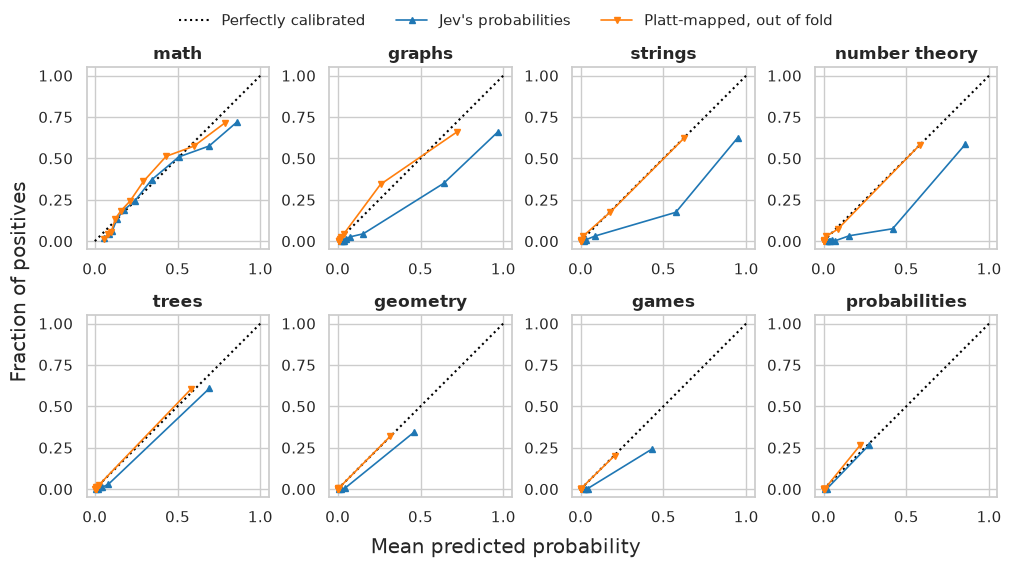

jev-statement-code-gepa: each tag's reliability on dev


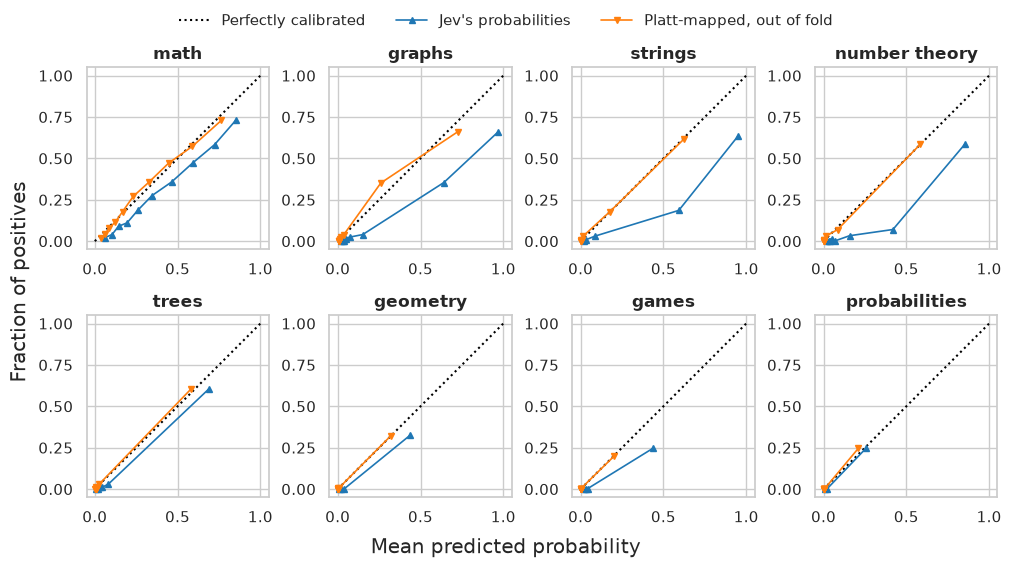

In [7]:
for base in BASES:
    print(f"{base}: each tag's reliability on dev")
    plot_reliability_grid(
        {"Jev's probabilities": dev_scores[base], "Platt-mapped, out of fold": platt[base]},
        dev_labels,
    )
    plt.show()

**Jev's probabilities are too high, and a Platt map of their logit, fitted out of fold, brings them to the diagonal: the mean expected calibration error falls from 0.053 to 0.011 for `jev-statement-code` and from 0.059 to 0.009 for `jev-statement-code-gepa`.**

- `jev-statement-code`: the error falls most on number theory (0.097 to 0.006), graphs (0.090 to 0.014) and strings (0.090 to 0.012); math changes least (0.044 to 0.041), and its curve stays close to the diagonal.
- `jev-statement-code-gepa`: the same tags fall the same way (number theory 0.097 to 0.005, graphs 0.090 to 0.014, strings 0.090 to 0.012), and math, whose words the search rewrote and whose curve lies below the diagonal, falls from 0.086 to 0.021.
- In the diagrams, Jev's curves lie below the diagonal for most tags, most of all for graphs, strings and number theory: among the problems Jev gives a tag a high probability, fewer have it than the probability says, so Jev overstates its tags.

A threshold rule that reads a probability needs it calibrated: half the best F1 is a probability that R2 can read on the Platt-mapped scale, and not on Jev's raw one.

### Which calibrator?

**Calibration in plain words.** A probability does two jobs. It ranks: a problem with a higher
`graphs` probability is more likely a graphs problem. And it is a number: among the problems
given 0.7, about 70 in 100 should have the tag. A calibrator fixes the second job only. It is a
small map, fitted on labelled problems, from Jev's probability to an honest one (it may learn,
say, that Jev's 0.70 means 0.45). The maps below increase, so within one fold they keep the
order of the problems.

**Why a threshold rule cares.** R0 picks the cut where F1 is highest. An increasing map moves
that cut with it, and the same problems stay above it, so one map applied to every problem
changes nothing for R0. Here each fold gets its own map, fitted on the other four folds, so a
few problems near a cut can move, and R0's macro F1 shifts only in its third decimal. A rule that reads the number itself does change: the cut 0.5 ("more likely than not") and
Lipton's cut F1\*/2 (on calibrated probabilities, the cut with the highest F1 is half that F1).
Both go wrong on probabilities that are too high, which is why R2 calibrates first.

**Six calibrators**, each fitted out of fold: fold k is mapped by the map fitted on the other
four folds, on dev only, and every logistic map is fitted to convergence, as R2's is.
scikit-learn's `CalibratedClassifierCV` wraps a classifier it can call; Jev is an API whose
answers are frozen, so the notebook fits the maps directly (`analysis/calibrators.py`).

| Calibrator | What it fits | Parameters per tag | Good at | Weak at |
|---|---|---|---|---|
| `none` | nothing: Jev's probabilities | 0 | | |
| `platt_logit` | a logistic regression on logit(p): R2's map | 2: a slope and a shift | probabilities too high and too sure | shapes that are not an S |
| `platt_raw` | a logistic regression on p, close to what `CalibratedClassifierCV(method="sigmoid")` fits on a probability (scikit-learn also smooths the targets, as Platt did) | 2 | a model's margins, its usual input | probabilities, whose S lives on the logit scale |
| `temperature` | `platt_logit` without its shift: one slope (1 / T), the binary form of `method="temperature"` | 1 | probabilities that are only too sure | probabilities too high on average |
| `beta` | a logistic regression on log p and -log(1 - p), both slopes kept at or above 0 so that the map never decreases (beta calibration; not in scikit-learn) | 3 | probabilities bunched near 0 or 1 | needs more data than Platt |
| `isotonic` | any increasing staircase (`IsotonicRegression`, `method="isotonic"`) | one per step | much data, any shape | a rare tag: it overfits, and its steps tie problems, which costs ranking |

Each calibrator is scored three ways. Its **Brier score and log loss** say how honest its numbers
are (lower is better; group-bootstrap intervals over all problem-tag pairs). Its **macro AUC and
macro average precision** say how well it ranks (an increasing map changes them only across
folds, since each fold has its own map). Its **macro F1 under three decision rules**, each
cross-fitted on its probabilities: the cut 0.5, the cut F1\*/2, and the F1 argmax (R0's rule),
each paired with `none` under the F1 argmax. The comparison is descriptive: R2 was fixed before
it, and nothing is chosen from it. `jev-statement-code-gepa`'s dev rows are in sample on folds
1-4 (its words were chosen there), so its table describes and does not compare honestly.

In [8]:
calibrated = {}
for base in BASES:
    calibrated[base] = calibrated_probabilities(dev_scores[base], dev_labels, folds)
    losses = calibration_table(calibrated[base], dev_labels, groups).xs(POOLED, level="tag")
    rules = method_scores(
        dev_labels,
        rule_predictions(calibrated[base], dev_labels, folds),
        groups,
        baseline=RULE_KEY.format(calibrator="none", rule="best_f1"),
    ).xs("macro_f1", level="metric")
    f1 = rules["f1"]
    f1.index = f1.index.str.split(" / ", expand=True).set_names(["calibrator", "rule"])
    table = pd.concat(
        [
            losses[
                ["brier", "brier_low", "brier_high", "log_loss", "log_loss_low", "log_loss_high"]
            ],
            ranking_table(calibrated[base], dev_labels),
            f1.unstack("rule")[list(DECISION_RULES)].add_prefix("macro_f1 "),
        ],
        axis="columns",
    ).loc[list(CALIBRATORS)]
    print(f"{base}: each calibrator on dev, out of fold")
    display(table.round(4))
    half = [RULE_KEY.format(calibrator=name, rule="at_half_best_f1") for name in CALIBRATORS]
    print(f"{base}: the cut F1*/2 against none under the F1 argmax, paired")
    display(rules.loc[half, ["f1", "delta", "delta_low", "delta_high"]].round(4))

jev-statement-code: each calibrator on dev, out of fold


,brier,brier_low,brier_high,log_loss,log_loss_low,log_loss_high,macro_auc,macro_ap,macro_f1 at_0.5,macro_f1 at_half_best_f1,macro_f1 best_f1
none,0.0499,0.0482,0.0515,0.1734,0.1684,0.1782,0.9536,0.7645,0.6901,0.6721,0.7293
platt_logit,0.0391,0.0377,0.0405,0.1292,0.1248,0.1341,0.9510,0.7648,0.7216,0.7379,0.7329
platt_raw,0.0400,0.0386,0.0414,0.1344,0.1296,0.1394,0.9441,0.7574,0.7235,0.7346,0.7340
temperature,0.0495,0.0479,0.0512,0.1672,0.1622,0.1722,0.9523,0.7674,0.6901,0.6775,0.7301
beta,0.0388,0.0375,0.0402,0.1273,0.1229,0.1320,0.9502,0.7595,0.7261,0.7336,0.7276
isotonic,0.0386,0.0373,0.0399,0.1356,0.1277,0.1437,0.9480,0.7445,0.7291,0.7302,0.7338


jev-statement-code: the cut F1*/2 against none under the F1 argmax, paired


,f1,delta,delta_low,delta_high
method,,,,
none / at_half_best_f1,0.6721,-0.0573,-0.0715,-0.0434
platt_logit / at_half_best_f1,0.7379,0.0086,0.0007,0.0173
platt_raw / at_half_best_f1,0.7346,0.0053,-0.0039,0.0151
temperature / at_half_best_f1,0.6775,-0.0519,-0.0662,-0.0379
beta / at_half_best_f1,0.7336,0.0042,-0.0047,0.0142
isotonic / at_half_best_f1,0.7302,0.0008,-0.0020,0.0037


jev-statement-code-gepa: each calibrator on dev, out of fold


,brier,brier_low,brier_high,log_loss,log_loss_low,log_loss_high,macro_auc,macro_ap,macro_f1 at_0.5,macro_f1 at_half_best_f1,macro_f1 best_f1
none,0.0504,0.0488,0.0520,0.1747,0.1699,0.1793,0.9549,0.7701,0.6953,0.6729,0.7302
platt_logit,0.0389,0.0375,0.0403,0.1281,0.1237,0.1329,0.9522,0.7688,0.7210,0.7355,0.7327
platt_raw,0.0397,0.0382,0.0411,0.1328,0.1281,0.1379,0.9456,0.7633,0.7276,0.7344,0.7344
temperature,0.0501,0.0485,0.0517,0.1681,0.1632,0.1730,0.9536,0.7707,0.6953,0.6763,0.7315
beta,0.0388,0.0374,0.0401,0.1269,0.1225,0.1315,0.9517,0.7665,0.7258,0.7366,0.7348
isotonic,0.0387,0.0374,0.0401,0.1357,0.1280,0.1443,0.9491,0.7477,0.7200,0.7302,0.7279


jev-statement-code-gepa: the cut F1*/2 against none under the F1 argmax, paired


,f1,delta,delta_low,delta_high
method,,,,
none / at_half_best_f1,0.6729,-0.0574,-0.0708,-0.0440
platt_logit / at_half_best_f1,0.7355,0.0052,-0.0037,0.0144
platt_raw / at_half_best_f1,0.7344,0.0041,-0.0046,0.0135
temperature / at_half_best_f1,0.6763,-0.0539,-0.0672,-0.0396
beta / at_half_best_f1,0.7366,0.0064,-0.0015,0.0146
isotonic / at_half_best_f1,0.7302,0.0000,0.0000,0.0000


jev-statement-code: reliability over all problem-tag pairs on dev, four calibrators


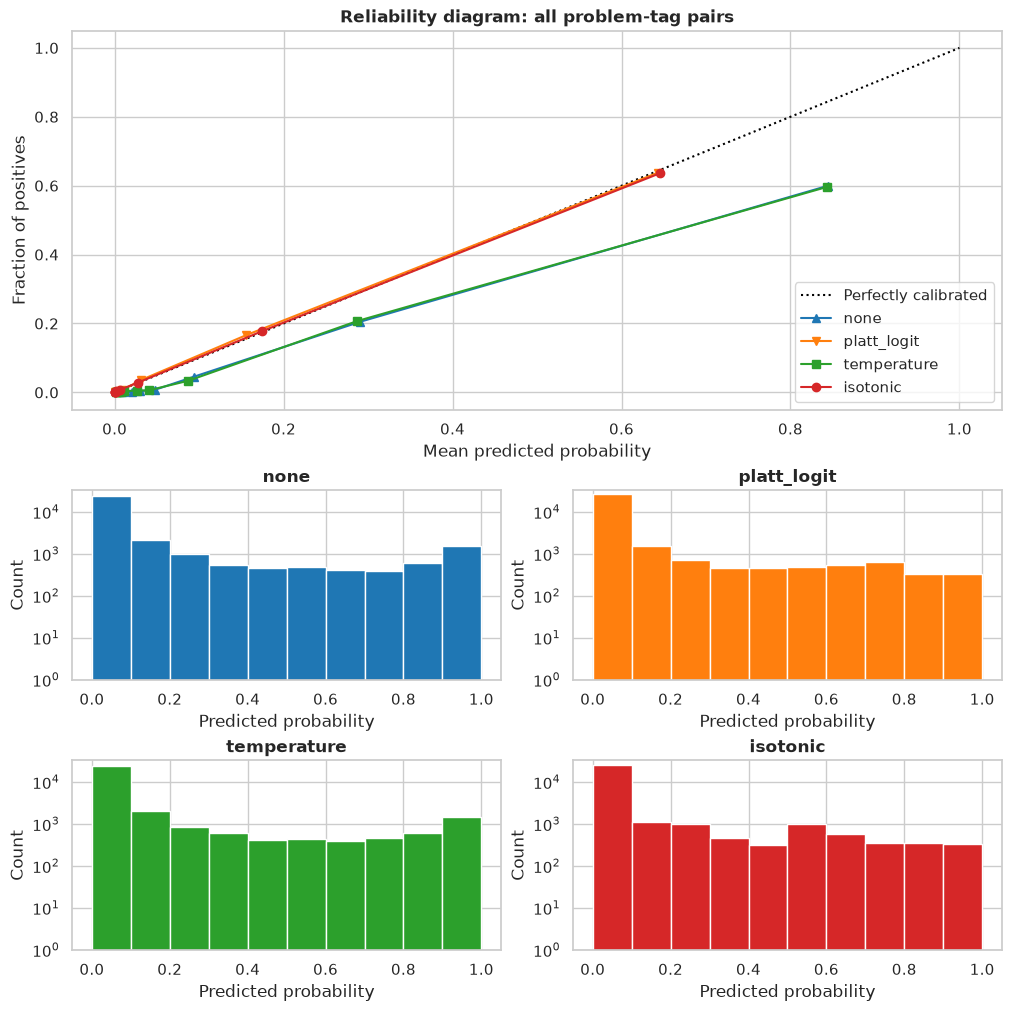

In [9]:
print(f"{CODE}: reliability over all problem-tag pairs on dev, four calibrators")
plot_reliability(
    {name: calibrated[CODE][name] for name in ("none", "platt_logit", "temperature", "isotonic")},
    dev_labels,
)
plt.show()

**Every calibrator with a shift makes Jev's probabilities more honest, by about a fifth of their Brier score; temperature scaling, which has no shift, barely moves them. Among the decision rules, only those that read the number change, and `platt_logit`, R2's map, gives the best cut at F1\*/2 on `jev-statement-code`.**

- Brier score on dev, `jev-statement-code`: `none` 0.0499 [0.0482, 0.0515], `platt_logit` 0.0391 [0.0377, 0.0405], `platt_raw` 0.0400, `temperature` 0.0495, `beta` 0.0388 and `isotonic` 0.0386. Log loss: 0.1734 [0.1684, 0.1782] for `none` against 0.1292 [0.1248, 0.1341] for `platt_logit`; `beta` is lowest, at 0.1273.
- Temperature fits one slope and no shift, so it can make Jev less sure but cannot lower its probabilities on average. Jev's are too high, so temperature moves the Brier score from 0.0499 to 0.0495 only.
- The F1 argmax (R0's rule) barely moves: from 0.728 (`beta`) to 0.734 (`platt_raw`), against 0.729 for `none`, a largest gap of 0.006. An increasing map keeps a fold's order; the gap comes from each fold having its own map.
- The rules that read the number do move. The cut 0.5 gives 0.690 on `none` and on `temperature`, against 0.722 to 0.729 with a shift. The cut F1\*/2 gives 0.672 on `none` and 0.678 on `temperature`, against 0.738 on `platt_logit`, a paired +0.009 [0.001, 0.017] over `none` under the F1 argmax; `platt_raw` gives +0.005 [-0.004, 0.015], `beta` +0.004 [-0.005, 0.014] and `isotonic` +0.001 [-0.002, 0.004].
- Ranking: `isotonic` ranks worst by macro average precision (0.7445 against 0.7645 for `none`), since its steps tie problems, and `platt_raw` worst by macro AUC (0.9441 against 0.9536). `platt_logit` keeps the average precision (0.7648) and loses 0.003 of AUC (0.9510). `beta`, whose slopes are kept at or above 0, has a macro average precision of 0.7595.
- `jev-statement-code-gepa` (in sample on folds 1-4) shows the same picture: Brier from 0.0504 to 0.0389 with `platt_logit`, the cut F1\*/2 from 0.673 on `none` to 0.736 on `platt_logit` (+0.005 [-0.004, 0.014]); there `beta` reaches 0.737 (+0.006 [-0.002, 0.015]).

`platt_logit`, R2's map, is the best trade for this rule on `jev-statement-code`: two parameters per tag, a Brier score within 0.0005 of the lowest, the average precision kept, and the highest F1 at F1\*/2. On the GEPA base, `beta` is level with it within the intervals.

**Read more.**

scikit-learn:
- [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html), the user guide
- [`CalibratedClassifierCV`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html) (`method="sigmoid"`, `"isotonic"` or `"temperature"`)
- [`calibration_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html) and [`CalibrationDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibrationDisplay.html), the reliability diagram
- [`IsotonicRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.isotonic.IsotonicRegression.html)
- [Tuning the decision threshold](https://scikit-learn.org/stable/modules/classification_threshold.html) (`TunedThresholdClassifierCV`, `FixedThresholdClassifier`)
- [`brier_score_loss`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html) and [`log_loss`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html)
- Examples: [probability calibration curves](https://scikit-learn.org/stable/auto_examples/calibration/plot_calibration_curve.html), [comparison of calibration of classifiers](https://scikit-learn.org/stable/auto_examples/calibration/plot_compare_calibration.html), [probability calibration of classifiers](https://scikit-learn.org/stable/auto_examples/calibration/plot_calibration.html), [post-tuning the decision threshold](https://scikit-learn.org/stable/auto_examples/model_selection/plot_tuned_decision_threshold.html)

Papers:
- Platt (1999), *Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods*: the sigmoid map.
- Zadrozny and Elkan (2002), *Transforming classifier scores into accurate multiclass probability estimates*: the isotonic map.
- Niculescu-Mizil and Caruana (2005), *Predicting good probabilities with supervised learning*: Platt against isotonic, by model and data size.
- Guo, Pleiss, Sun and Weinberger (2017), [*On calibration of modern neural networks*](https://arxiv.org/abs/1706.04599): temperature scaling.
- Kull, Silva Filho and Flach (2017), [*Beta calibration*](https://proceedings.mlr.press/v54/kull17a.html).
- Lipton, Elkan and Narayanaswamy (2014), [*Thresholding classifiers to maximize F1 score*](https://arxiv.org/abs/1402.1892): the cut at half the best F1.

## 3. Why the F1-argmax threshold moves

The thresholds of `probabilities` that each fold gets, chosen on the four other folds, under R0
and under R2, for both bases. Then the committed stability record of each twin
(`tuning/stability.csv`): per tag, the five fold thresholds under each rule, their spread, and
how many dev problems get another 0/1 depending on which four folds chose the threshold.

In [10]:
spread = pd.concat(
    {
        (base, rule): fold_thresholds[base][rule]["probabilities"]
        for base in BASES
        for rule in ("R0", "R2")
    },
    axis="columns",
)
display(spread.round(3))
stability = pd.concat(
    {twin: pd.read_csv(method_dir(twin) / TUNING_FOLDER / STABILITY_FILE) for twin in TWINS},
    names=["twin", "row"],
)
stability.round(3)

jev-statement-code        jev-statement-code-gepa       
                     R0     R2                      R0     R2
fold                                                         
0                 0.930  0.755                   0.810  0.665
1                 0.870  0.655                   0.770  0.545
2                 0.870  0.695                   0.125  0.585
3                 0.855  0.685                   0.325  0.595
4                 0.870  0.685                   0.325  0.595

tag rule  fold_0  fold_1  fold_2  \
twin                          row                                               
jev-statement-code-platt      0             math   R0   0.335   0.335   0.335   
                              1             math   R2   0.375   0.365   0.375   
                              2           graphs   R0   0.805   0.815   0.745   
                              3           graphs   R2   0.835   0.845   0.825   
                              4          strings   R0   0.875   0.915   0.895   
                              5          strings   R2   0.835   0.845   0.835   
                              6    number theory   R0   0.835   0.825   0.745   
                              7    number theory   R2   0.765   0.765   0.765   
                              8            trees   R0   0.795   0.785   0.785   
                              9            trees   R2   0.685   0.675   0.645   
                              10        geometry   R0   0.610   0.635   0.615   
                              11        geometry   R2   0.625   0.635   0.655   
                              12           games   R0   0.820   0.820   0.925   
                              13           games   R2   0.805   0.815   0.835   
                              14   probabilities   R0   0.930   0.870   0.870   
                              15   probabilities   R2   0.755   0.655   0.695   
jev-statement-code-gepa-platt 0             math   R0   0.425   0.395   0.395   
                              1             math   R2   0.445   0.435   0.445   
                              2           graphs   R0   0.795   0.775   0.785   
                              3           graphs   R2   0.835   0.845   0.825   
                              4          strings   R0   0.925   0.915   0.895   
                              5          strings   R2   0.835   0.845   0.835   
                              6    number theory   R0   0.775   0.815   0.715   
                              7    number theory   R2   0.765   0.765   0.765   
                              8            trees   R0   0.785   0.670   0.665   
                              9            trees   R2   0.685   0.675   0.645   
                              10        geometry   R0   0.600   0.645   0.600   
                              11        geometry   R2   0.625   0.635   0.655   
                              12           games   R0   0.785   0.785   0.785   
                              13           games   R2   0.805   0.815   0.835   
                              14   probabilities   R0   0.810   0.770   0.125   
                              15   probabilities   R2   0.665   0.545   0.585   

                                   fold_3  fold_4  spread  final  flips  
twin                          row                                        
jev-statement-code-platt      0     0.335   0.335   0.000  0.335      0  
                              1     0.365   0.375   0.010  0.375     26  
                              2     0.705   0.805   0.110  0.745     41  
                              3     0.825   0.825   0.020  0.825     14  
                              4     0.835   0.915   0.080  0.895    113  
                              5     0.835   0.845   0.010  0.835      9  
                              6     0.845   0.745   0.100  0.695     87  
                              7     0.765   0.765   0.000  0.765      0  
                              8     0.645   0.785   0.150  0.645     20  
                              9     0.625   0.665   0.060  0.655      8  
                              10    0.695   0.480   0.215  0.615     26  
                              11    0.625   0.645   0.030  0.635      6  
                              12    0.840   0.740   0.185  0.820     21  
                              13    0.805   0.815   0.030  0.815      2  
                              14    0.855   0.870   0.075  0.870      2  
                              15

Why `probabilities` moves: its dev F1 at each cut of Jev's 0.01 grid, on every dev problem
(the thick line) and on the four folds that choose each fold's threshold (the thin lines), with
the final thresholds of R0 and R2. The table lists the runs of cuts whose F1 is within 0.01 of
the highest one (`curve_peaks`), with the positives and negatives each run's best cut predicts:
a low cut catches more positives and more negatives, at about the same F1.

jev-statement-code: the runs of cuts within 0.01 of the highest dev F1 of probabilities


,start,end,threshold,f1,below_max,positives,negatives
peak,,,,,,,
0,0.815,0.945,0.895,0.7634,0.0,50,7


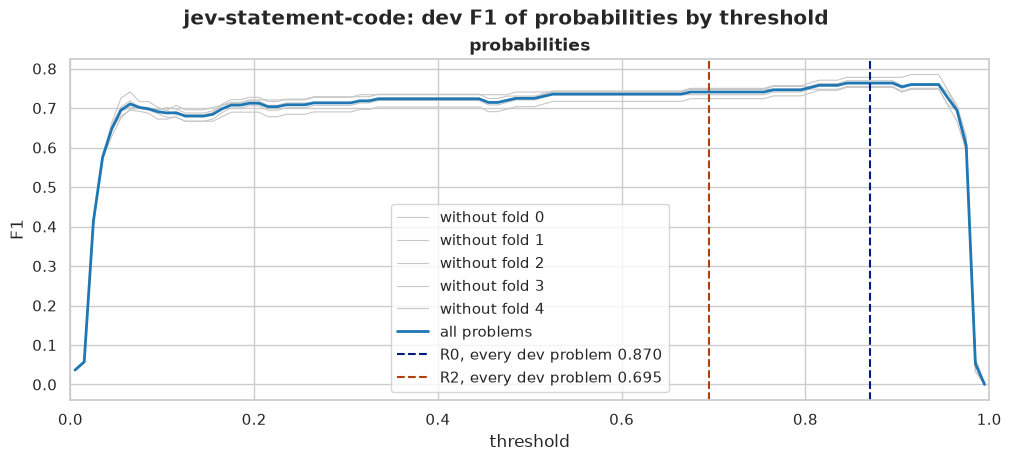

jev-statement-code-gepa: the runs of cuts within 0.01 of the highest dev F1 of probabilities


,start,end,threshold,f1,below_max,positives,negatives
peak,,,,,,,
0,0.125,0.145,0.125,0.7602,0.0000,65,32
1,0.315,0.325,0.325,0.7600,0.0002,57,19
2,0.405,0.435,0.435,0.7518,0.0085,53,14
3,0.735,0.815,0.795,0.7576,0.0027,50,8


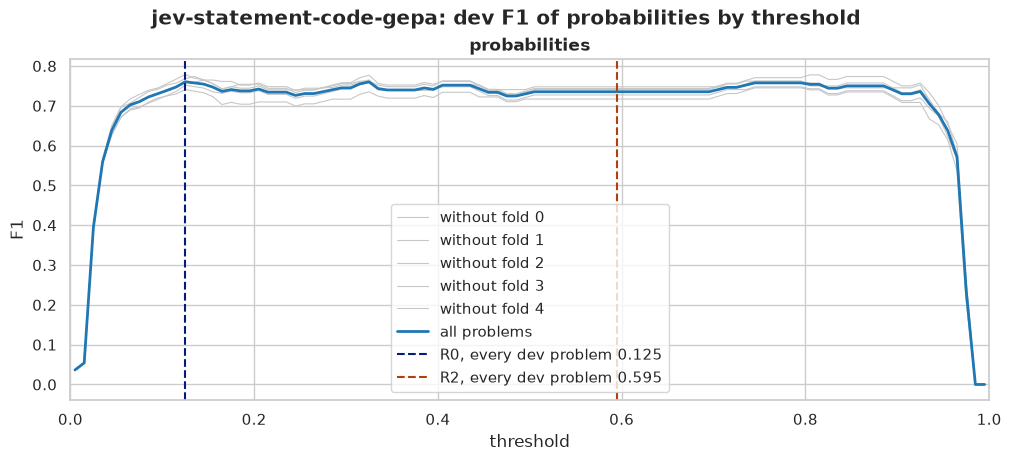

In [11]:
for base in BASES:
    scores, truth = dev_scores[base]["probabilities"], dev_labels["probabilities"]
    curve = f1_curve(scores, truth)
    peaks = curve_peaks(curve)
    peaks["positives"] = [int(((scores >= cut) & (truth == 1)).sum()) for cut in peaks["threshold"]]
    peaks["negatives"] = [int(((scores >= cut) & (truth == 0)).sum()) for cut in peaks["threshold"]]
    print(f"{base}: the runs of cuts within 0.01 of the highest dev F1 of probabilities")
    display(peaks.round(4))
    rules = {
        "R0, every dev problem": final_thresholds[base]["probabilities"],
        "R2, every dev problem": final_thresholds[TWIN_OF[base]]["probabilities"],
    }
    figure = plot_f1_curve(curve, rules, folds=fold_curves(scores, truth, folds))
    figure.suptitle(f"{base}: dev F1 of probabilities by threshold", fontweight="bold")
    plt.show()

**R2's fold thresholds stay closer together than R0's on most tags, and far fewer dev problems depend on which four folds chose the threshold. R0 jumps most on the GEPA method's `probabilities`, whose dev F1 curve has four nearly equal runs.**

- Spread of the five fold thresholds, R0 then R2. `jev-statement-code`: narrower under R2 on six tags (e.g. geometry 0.215 to 0.030, games 0.185 to 0.030, number theory 0.100 to 0.000), wider on math (0.000 to 0.010) and on `probabilities` (0.075 to 0.100: R0 0.930, 0.870, 0.870, 0.855, 0.870; R2 0.755, 0.655, 0.695, 0.685, 0.685). `jev-statement-code-gepa`: narrower under R2 on six tags, equal on graphs (0.020), wider on games (0.000 to 0.030); on `probabilities`, 0.685 under R0 (0.810, 0.770, 0.125, 0.325, 0.325) against 0.120 under R2 (0.665, 0.545, 0.585, 0.595, 0.595).
- Dev problems whose 0/1 depends on the folds, R0 then R2. `jev-statement-code`: strings 113 to 9, number theory 87 to 0, graphs 41 to 14, geometry 26 to 6, games 21 to 2 and `probabilities` 2 to 1, but math 0 to 26. `jev-statement-code-gepa`: strings 144 to 12, number theory 86 to 0, `probabilities` 41 to 0 and math 88 to 46, but graphs 8 to 15.
- The GEPA `probabilities` curve has four runs of cuts within 0.01 of its highest dev F1: 0.125-0.145 (0.7602; its best cut predicts the tag on 65 problems that have it and 32 that do not), 0.315-0.325 (0.7600; 57 and 19), 0.405-0.435 (0.7518; 53 and 14) and 0.735-0.815 (0.7576; 50 and 8). `jev-statement-code`'s has one run, 0.815-0.945 (0.7634; 50 and 7).
- R0's fold thresholds show which run each fold's curve peaks in: the high run for folds 0 and 1 (0.810 and 0.770), a low run for folds 2 to 4 (0.125, 0.325 and 0.325). R0's final threshold, chosen on every dev problem, is 0.125.

R2 does not jump between distant peaks, because it reads the height of the curve, its best F1, which is nearly the same in every run. Its fold thresholds still move, by up to 12 grid steps on `probabilities`, as each fold's Platt map moves with the problems it is fitted on.

## 4. The declared comparison and the nested choice

The committed dev-only record of each twin (`tuning/rules.csv`): R0, R1 and R2, each
cross-fitted over the five dev folds, with each rule's out-of-fold macro F1 and its paired
difference from R0 (group bootstrap intervals). R0's and R2's rows are checked against the
frozen dev predictions of the base and of the twin. Then each tag's F1 under each rule.

In [12]:
rules = pd.concat(
    {
        twin: pd.read_csv(
            method_dir(twin) / TUNING_FOLDER / RULES_FILE, index_col=["rule", "metric"]
        )
        for twin in TWINS
    },
    names=["twin"],
)
for twin, base in PLATT_BASES.items():
    for rule, name in (("R0", base), ("R2", twin)):
        recorded = rules.loc[(twin, rule, "macro_f1"), "f1"]
        frozen_f1 = evaluate(dev_labels, dev_by_method[name]).macro_f1
        assert np.isclose(recorded, frozen_f1, rtol=0, atol=1e-12), (twin, rule)
display(rules.xs("macro_f1", level="metric").round(3))
per_tag = rules["f1"].unstack("rule")
per_tag[per_tag.index.get_level_values("metric").isin(TAGS)].round(3)

f1  f1_low  f1_high  delta  delta_low  \
twin                          rule                                             
jev-statement-code-platt      R0    0.729   0.710    0.746  0.000      0.000   
                              R1    0.722   0.702    0.739 -0.008     -0.016   
                              R2    0.738   0.720    0.755  0.009      0.001   
jev-statement-code-gepa-platt R0    0.730   0.712    0.746  0.000      0.000   
                              R1    0.721   0.702    0.739 -0.009     -0.020   
                              R2    0.737   0.718    0.753  0.006     -0.002   

                                    delta_high  
twin                          rule              
jev-statement-code-platt      R0         0.000  
                              R1         0.001  
                              R2         0.017  
jev-statement-code-gepa-platt R0         0.000  
                              R1         0.000  
                              R2         0.015

rule                                            R0     R1     R2
twin                          metric                            
jev-statement-code-platt      games          0.830  0.859  0.866
                              geometry       0.761  0.773  0.781
                              graphs         0.704  0.673  0.703
                              math           0.638  0.535  0.630
                              number theory  0.687  0.705  0.705
                              probabilities  0.754  0.746  0.741
                              strings        0.660  0.676  0.668
                              trees          0.801  0.806  0.810
jev-statement-code-gepa-platt games          0.874  0.859  0.866
                              geometry       0.772  0.772  0.787
                              graphs         0.711  0.667  0.702
                              math           0.619  0.544  0.620
                              number theory  0.680  0.705  0.707
                              probabilities  0.720  0.735  0.735
                              strings        0.660  0.680  0.671
                              trees          0.805  0.806  0.806

The nested choice (`tuning/nested.csv`): for each outer fold, the rule with the best
cross-fitted macro F1 inside the four other folds, then applied to the outer fold. If it picks
the same rule in every outer fold, choosing the rule on dev added no optimism to the comparison
above. It is reported, never acted on: the twins use R2.

In [13]:
for twin in TWINS:
    print(f"{twin}: the rule chosen in each outer fold: {params_by_twin[twin]['nested_choice']}")
    display(pd.read_csv(method_dir(twin) / TUNING_FOLDER / NESTED_FILE).round(4))

jev-statement-code-platt: the rule chosen in each outer fold: ['R2', 'R2', 'R2', 'R2', 'R2']


,fold,chosen,inner_macro_f1_R0,inner_macro_f1_R1,inner_macro_f1_R2,fold_macro_f1,nested_macro_f1
0,0,R2,0.7343,0.7204,0.7365,0.7420,0.7379
1,1,R2,0.7346,0.7207,0.7394,0.7277,0.7379
2,2,R2,0.7404,0.7249,0.7427,0.7139,0.7379
3,3,R2,0.7315,0.7236,0.7357,0.7459,0.7379
4,4,R2,0.7254,0.7166,0.7340,0.7585,0.7379


jev-statement-code-gepa-platt: the rule chosen in each outer fold: ['R2', 'R2', 'R2', 'R2', 'R2']


,fold,chosen,inner_macro_f1_R0,inner_macro_f1_R1,inner_macro_f1_R2,fold_macro_f1,nested_macro_f1
0,0,R2,0.7294,0.7203,0.7364,0.7382,0.7367
1,1,R2,0.7318,0.7195,0.7379,0.7299,0.7367
2,2,R2,0.7404,0.7258,0.7407,0.7110,0.7367
3,3,R2,0.7285,0.7220,0.7354,0.7458,0.7367
4,4,R2,0.7283,0.7130,0.7315,0.7570,0.7367


**R2 is the best of the three rules in every outer fold for both twins: +0.009 [0.001, 0.017] over R0 for `jev-statement-code-platt` and +0.006 [-0.002, 0.015] for `jev-statement-code-gepa-platt`, while R1, the cut 0.5 on Platt's scale, loses F1.**

- `jev-statement-code-platt`: R0 0.729 [0.710, 0.746], R1 0.722 (-0.008 [-0.016, 0.001]), R2 0.738 [0.720, 0.755].
- `jev-statement-code-gepa-platt`: R0 0.730 [0.712, 0.746], R1 0.721 (-0.009 [-0.020, 0.000]), R2 0.737 [0.718, 0.753]; R2's interval against R0 contains 0.
- Per tag, R2 against R0. `jev-statement-code-platt` gains most on games (0.830 to 0.866), geometry (0.761 to 0.781) and number theory (0.687 to 0.705), and loses on probabilities (0.754 to 0.741) and math (0.638 to 0.630). `jev-statement-code-gepa-platt` gains on number theory (0.680 to 0.707), geometry (0.772 to 0.787) and probabilities (0.720 to 0.735), and loses on games (0.874 to 0.866) and graphs (0.711 to 0.702).
- The nested choice picks R2 in all five outer folds of both twins, so the nested macro F1 equals R2's out-of-fold one (0.7379 and 0.7367): choosing among the three declared rules adds no optimism. It measures only that choice: R2 itself was proposed after dev was read (ADR 0011), so its gain is somewhat optimistic beyond it.
- R1 loses most on math (0.638 to 0.535, and 0.619 to 0.544): on calibrated probabilities the F1-optimal cut for a tag whose best F1 is about 0.64 is about 0.32 (Lipton), so a cut at 0.5 misses many of its problems.

The gain is small, and for the GEPA twin within the noise. The record was committed before either twin was frozen, and both use R2 whatever it shows.

## 5. Each twin against its base on dev

Each twin's dev predictions against its base's, paired, on every dev problem: out of fold for
`jev-statement-code-platt`, in sample for `jev-statement-code-gepa-platt` (its words were chosen
on folds 1-4).

In [14]:
dev_paired = pd.concat(
    {
        twin: method_scores(
            dev_labels,
            {base: dev_by_method[base], twin: dev_by_method[twin]},
            groups,
            baseline=base,
        ).loc[twin]
        for twin, base in PLATT_BASES.items()
    },
    names=["twin"],
)
dev_paired.round(3)

f1  f1_low  f1_high  delta  \
twin                          metric                                         
jev-statement-code-platt      macro_f1       0.738   0.720    0.755  0.009   
                              micro_f1       0.686   0.672    0.700  0.003   
                              math           0.630   0.607    0.653 -0.008   
                              graphs         0.703   0.670    0.736 -0.001   
                              strings        0.668   0.630    0.706  0.008   
                              number theory  0.705   0.660    0.747  0.018   
                              trees          0.810   0.768    0.844  0.009   
                              geometry       0.781   0.724    0.832  0.020   
                              games          0.866   0.806    0.917  0.036   
                              probabilities  0.741   0.652    0.818 -0.013   
jev-statement-code-gepa-platt macro_f1       0.737   0.718    0.753  0.006   
                              micro_f1       0.681   0.666    0.694  0.005   
                              math           0.620   0.596    0.643  0.001   
                              graphs         0.702   0.669    0.735 -0.009   
                              strings        0.671   0.632    0.710  0.011   
                              number theory  0.707   0.662    0.748  0.027   
                              trees          0.806   0.764    0.840  0.001   
                              geometry       0.787   0.729    0.838  0.015   
                              games          0.866   0.806    0.917 -0.008   
                              probabilities  0.735   0.647    0.814  0.015   

                                             delta_low  delta_high  
twin                          metric                                
jev-statement-code-platt      macro_f1           0.001       0.017  
                              micro_f1          -0.003       0.008  
                              math              -0.016      -0.000  
                              graphs            -0.011       0.009  
                              strings           -0.010       0.028  
                              number theory     -0.002       0.041  
                              trees             -0.006       0.026  
                              geometry           0.000       0.044  
                              games              0.001       0.078  
                              probabilities     -0.043       0.018  
jev-statement-code-gepa-platt macro_f1          -0.002       0.015  
                              micro_f1          -0.001       0.010  
                              math              -0.007       0.009  
                              graphs            -0.021       0.002  
                              strings           -0.010       0.033  
                              number theory      0.007       0.047  
                              trees             -0.011       0.013  
                              geometry          -0.004       0.037  
                              games             -0.033       0.012  
                              probabilities     -0.039       0.071

The honest comparison of the searched words: fold 0, which the GEPA search never read. On
fold 0 every method's thresholds come from folds 1-4, and no method saw a fold-0 label. First the
four methods against `jev-statement-code`, then `jev-statement-code-gepa-platt` against its
base.

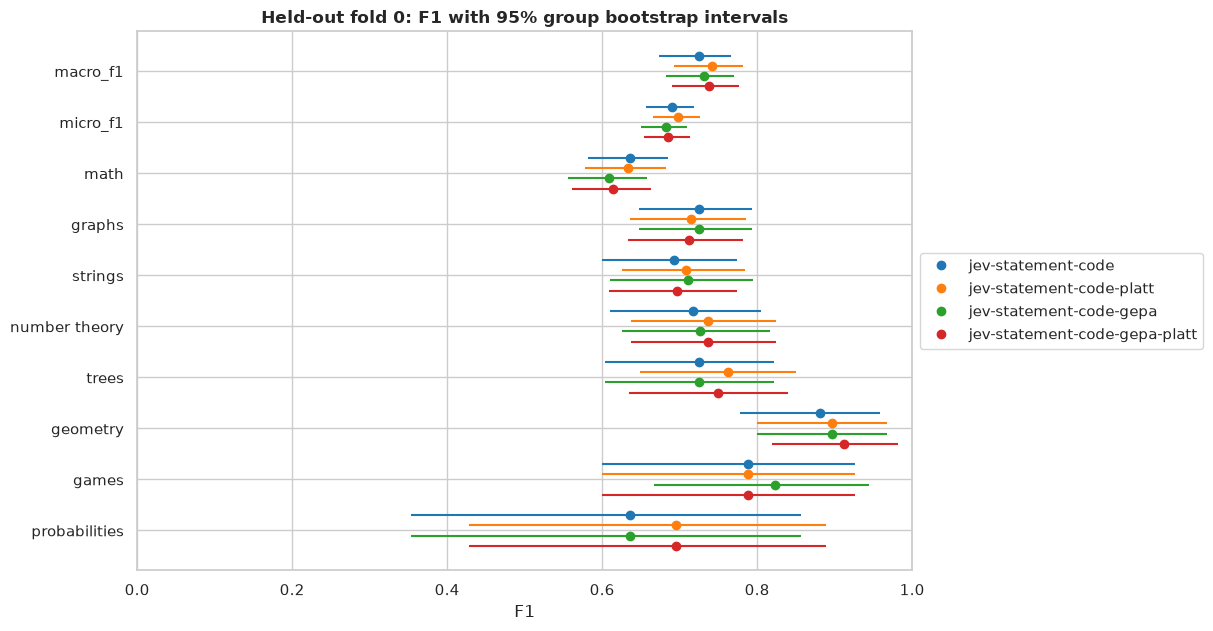

,f1,f1_low,f1_high,delta,delta_low,delta_high
method,,,,,,
jev-statement-code,0.725,0.673,0.766,0.000,0.000,0.000
jev-statement-code-platt,0.742,0.693,0.781,0.017,0.001,0.040
jev-statement-code-gepa,0.732,0.682,0.770,0.006,-0.006,0.022
jev-statement-code-gepa-platt,0.738,0.690,0.776,0.013,-0.003,0.037


,f1,f1_low,f1_high,delta,delta_low,delta_high
metric,,,,,,
macro_f1,0.738,0.690,0.776,0.007,-0.013,0.030
micro_f1,0.685,0.654,0.713,0.003,-0.007,0.014
math,0.614,0.561,0.663,0.005,-0.007,0.017
graphs,0.712,0.634,0.782,-0.012,-0.037,0.011
strings,0.696,0.609,0.774,-0.015,-0.076,0.046
number theory,0.737,0.637,0.824,0.011,0.000,0.038
trees,0.750,0.634,0.840,0.025,-0.023,0.080
geometry,0.912,0.820,0.981,0.016,0.000,0.057
games,0.788,0.600,0.927,-0.036,-0.127,0.000


In [15]:
held_out_methods = {
    name: dev_by_method[name][held_out] for name in (CODE, TWIN_OF[CODE], GEPA, TWIN_OF[GEPA])
}
held_out_scores = method_scores(
    dev_labels[held_out], held_out_methods, groups[held_out], baseline=CODE
)
ax = plot_method_f1(held_out_scores)
ax.figure.set_size_inches(10, 7)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title(f"Held-out fold {SEARCH_HELD_OUT_FOLD}: F1 with 95% group bootstrap intervals")
plt.show()
display(held_out_scores.xs("macro_f1", level="metric").round(3))
gepa_pair = method_scores(
    dev_labels[held_out],
    {GEPA: held_out_methods[GEPA], TWIN_OF[GEPA]: held_out_methods[TWIN_OF[GEPA]]},
    groups[held_out],
    baseline=GEPA,
)
gepa_pair.loc[TWIN_OF[GEPA]].round(3)

**On all of dev, each twin's macro F1 is above its base's, clearly for `jev-statement-code-platt` and within the noise for the GEPA twin. On the held-out fold 0, `jev-statement-code-platt` is the only method whose interval against `jev-statement-code` excludes 0.**

- All of dev, paired with the base. `jev-statement-code-platt`: macro F1 0.738, +0.009 [0.001, 0.017]; micro F1 +0.003 [-0.003, 0.008]. `jev-statement-code-gepa-platt`, in sample since its words were chosen on folds 1-4: 0.737, +0.006 [-0.002, 0.015]; micro F1 +0.005 [-0.001, 0.010]. Both micro F1 intervals contain 0.
- Per tag, `jev-statement-code-platt` gains on games (+0.036 [0.001, 0.078]) and geometry (+0.020 [0.000, 0.044]), and loses a little on math (-0.008 [-0.016, -0.000]).
- Fold 0, against `jev-statement-code` (0.725 [0.673, 0.766]): `jev-statement-code-platt` 0.742, +0.017 [0.001, 0.040]; `jev-statement-code-gepa` 0.732, +0.006 [-0.006, 0.022]; `jev-statement-code-gepa-platt` 0.738, +0.013 [-0.003, 0.037].
- Fold 0, the GEPA twin against its base: +0.007 [-0.013, 0.030] in macro F1, with probabilities +0.059 [0.000, 0.215] and games -0.036 [-0.127, 0.000], on 806 problems with few positives of either tag.

The intervals that contain 0 say that the rule's gain is small next to the sampling noise of 3,988 dev problems, and the gain of `jev-statement-code-platt` is somewhat optimistic, since R2 was proposed after dev was read. On fold 0, the GEPA twin's honest comparison, it is not separated from its base.

## 6. The test set, reported once

Each method's frozen test predictions, scored once, side by side. The twins are `test_informed`:
the idea of their threshold rule came after the test drop of `jev-statement-code-gepa` was read,
so these numbers are references, not an independent test of the rule, and nothing is chosen
from them (ADR 0001). `jev-statement-code`, `jev-statement-code-gepa`, `tfidf` and `label_prior`
are references too.

In [16]:
for twin in TWINS:
    print(f"{twin} is test_informed: {records[twin].method_entries['test_informed']['note']}")
reported = [*TWINS, *BASES, TFIDF, PRIOR]
test_results = {
    name: evaluate(
        test_labels,
        test_by_method[name],
        release_years=release_years(test),
        groups=test["group"],
    )
    for name in reported
}
display(pd.DataFrame({name: result.overall_f1() for name, result in test_results.items()}).round(3))
test_summary = pd.DataFrame(
    {name: result.summary.loc[ALL_PROBLEMS] for name, result in test_results.items()}
).T
interval_columns = ["macro_f1", "macro_f1_low", "macro_f1_high"]
test_summary[[*interval_columns, "micro_f1", "micro_f1_low", "micro_f1_high"]].round(3)

jev-statement-code-platt is test_informed: the rule was proposed after the test drop of jev-statement-code-gepa was read
jev-statement-code-gepa-platt is test_informed: the rule was proposed after the test drop of jev-statement-code-gepa was read


,jev-statement-code-platt,jev-statement-code-gepa-platt,jev-statement-code,jev-statement-code-gepa,tfidf,label_prior
metric,,,,,,
macro_f1,0.745,0.741,0.751,0.727,0.689,0.149
micro_f1,0.684,0.679,0.694,0.677,0.633,0.158
math,0.647,0.640,0.659,0.636,0.619,0.441
graphs,0.703,0.698,0.713,0.703,0.557,0.196
strings,0.636,0.638,0.663,0.660,0.660,0.158
number theory,0.659,0.663,0.659,0.663,0.518,0.135
trees,0.767,0.756,0.767,0.756,0.772,0.119
geometry,0.781,0.781,0.781,0.781,0.706,0.064
games,0.927,0.927,0.927,0.905,0.878,0.041


,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high
jev-statement-code-platt,0.745,0.714,0.772,0.684,0.657,0.710
jev-statement-code-gepa-platt,0.741,0.709,0.767,0.679,0.652,0.705
jev-statement-code,0.751,0.720,0.777,0.694,0.668,0.719
jev-statement-code-gepa,0.727,0.692,0.758,0.677,0.650,0.703
tfidf,0.689,0.649,0.721,0.633,0.604,0.661
label_prior,0.149,0.139,0.158,0.158,0.148,0.168


Paired on the test set: each twin against its base, then `jev-statement-code-gepa` and its
twin against `jev-statement-code`, the comparison whose drop started this work.

In [17]:
paired_test = pd.concat(
    {
        twin: method_scores(
            test_labels,
            {base: test_by_method[base], twin: test_by_method[twin]},
            test["group"],
            baseline=base,
        ).loc[twin]
        for twin, base in PLATT_BASES.items()
    },
    names=["twin"],
)
display(paired_test.round(3))
against_code = method_scores(
    test_labels,
    {name: test_by_method[name] for name in (CODE, GEPA, TWIN_OF[GEPA])},
    test["group"],
    baseline=CODE,
)
against_code.xs("macro_f1", level="metric").round(3)

f1  f1_low  f1_high  delta  \
twin                          metric                                         
jev-statement-code-platt      macro_f1       0.745   0.714    0.772 -0.006   
                              micro_f1       0.684   0.657    0.710 -0.010   
                              math           0.647   0.601    0.690 -0.012   
                              graphs         0.703   0.634    0.768 -0.010   
                              strings        0.636   0.558    0.710 -0.028   
                              number theory  0.659   0.567    0.739 -0.001   
                              trees          0.767   0.673    0.844  0.000   
                              geometry       0.781   0.655    0.886  0.000   
                              games          0.927   0.829    1.000  0.000   
                              probabilities  0.842   0.690    0.950  0.000   
jev-statement-code-gepa-platt macro_f1       0.741   0.709    0.767  0.014   
                              micro_f1       0.679   0.652    0.705  0.002   
                              math           0.640   0.596    0.683  0.005   
                              graphs         0.698   0.628    0.764 -0.005   
                              strings        0.638   0.560    0.714 -0.021   
                              number theory  0.663   0.571    0.745  0.000   
                              trees          0.756   0.661    0.835  0.000   
                              geometry       0.781   0.655    0.886  0.000   
                              games          0.927   0.829    1.000  0.022   
                              probabilities  0.821   0.652    0.936  0.109   

                                             delta_low  delta_high  
twin                          metric                                
jev-statement-code-platt      macro_f1          -0.013       0.001  
                              micro_f1          -0.020       0.001  
                              math              -0.032       0.005  
                              graphs            -0.034       0.014  
                              strings           -0.053      -0.003  
                              number theory     -0.046       0.039  
                              trees              0.000       0.000  
                              geometry           0.000       0.000  
                              games              0.000       0.000  
                              probabilities      0.000       0.000  
jev-statement-code-gepa-platt macro_f1           0.001       0.028  
                              micro_f1          -0.008       0.013  
                              math              -0.015       0.024  
                              graphs            -0.024       0.010  
                              strings           -0.063       0.022  
                              number theory      0.000       0.000  
                              trees              0.000       0.000  
                              geometry           0.000       0.000  
                              games              0.000       0.079  
                              probabilities      0.027       0.201

,f1,f1_low,f1_high,delta,delta_low,delta_high
method,,,,,,
jev-statement-code,0.751,0.720,0.777,0.000,0.000,0.000
jev-statement-code-gepa,0.727,0.692,0.758,-0.025,-0.041,-0.010
jev-statement-code-gepa-platt,0.741,0.709,0.767,-0.011,-0.022,-0.001


**`test_informed`: the rule was proposed after the test drop of `jev-statement-code-gepa` was read, so these test scores are references, scored once, and choose nothing.**

- Test macro F1: `jev-statement-code-platt` 0.745 [0.714, 0.772] (micro F1 0.684) and `jev-statement-code-gepa-platt` 0.741 [0.709, 0.767] (micro F1 0.679), against `jev-statement-code` 0.751 [0.720, 0.777], `jev-statement-code-gepa` 0.727 [0.692, 0.758], `tfidf` 0.689 and `label_prior` 0.149.
- Each twin against its base, paired. `jev-statement-code-platt`: -0.006 [-0.013, 0.001], with strings (-0.028 [-0.053, -0.003]) the one tag whose interval excludes 0. `jev-statement-code-gepa-platt`: +0.014 [0.001, 0.028], almost all from probabilities, 0.711 to 0.821 (+0.109 [0.027, 0.201]), where R2's threshold 0.595 replaces R0's 0.125.
- Against `jev-statement-code`: `jev-statement-code-gepa` -0.025 [-0.041, -0.010], and its twin -0.011 [-0.022, -0.001]. The twin recovers 0.014 of the GEPA method's 0.025 loss, and stays below `jev-statement-code`.

On test, the rule repairs the one tag where R0 jumped between distant peaks (the GEPA method's probabilities) and gains nothing elsewhere; the test set chooses nothing, and the command line's default stays `jev-statement-code`.

## 7. Takeaways and next steps

**Results**
- **Section 2, calibration.** Jev overstates its tags. A Platt map of the logit, fitted out of fold, lowers the mean expected calibration error from 0.053 to 0.011 (`jev-statement-code`) and from 0.059 to 0.009 (`jev-statement-code-gepa`). Of six calibrators, every one with a shift lowers the Brier score from 0.0499 to about 0.039, temperature leaves it at 0.0495, and the cut F1\*/2 reaches 0.672 on Jev's probabilities against 0.738 on `platt_logit`'s.
- **Section 3, stability.** On the GEPA method's `probabilities`, R0's fold thresholds spread over 0.685 (0.125 to 0.810) and 41 dev problems depend on the folds; R2's spread over 0.120 and none depends on them. R2's spread is narrower on six tags of eight for each base. For `jev-statement-code`, R2 cuts the dependent problems from 113 to 9 on strings and from 87 to 0 on number theory, at a cost on math (0 to 26).
- **Section 4, the declared comparison.** R2 against R0, out of fold: +0.009 [0.001, 0.017] and +0.006 [-0.002, 0.015]; R1 loses (-0.008 and -0.009); the nested choice picks R2 in all five outer folds of both twins.
- **Section 5, dev.** On fold 0, against `jev-statement-code`: +0.017 [0.001, 0.040] for `jev-statement-code-platt` and +0.013 [-0.003, 0.037] for the GEPA twin; the GEPA twin against its base, +0.007 [-0.013, 0.030].
- **Section 6, test, reported once (`test_informed`).** 0.745 and 0.741, against 0.751 for `jev-statement-code`. `jev-statement-code-gepa-platt` against its base: +0.014 [0.001, 0.028], almost all from probabilities (0.711 to 0.821). `jev-statement-code-platt` against its base: -0.006 [-0.013, 0.001].

R2 is a more stable threshold rule than R0. It reads the height of each tag's F1 curve, so it does not jump between distant peaks, its fold thresholds are closer together on most tags, and far fewer dev problems depend on which folds chose them. It sends no request and gains little in macro F1: +0.009 on dev for `jev-statement-code`, somewhat optimistic since R2 was proposed after dev was read, and an interval that contains 0 for the GEPA twin. On test, it repairs most of the GEPA method's loss on probabilities, but not the rest. Both twins are `test_informed`, so neither is ever the command line's default, which stays `jev-statement-code`.

**On the test set, the calibrated rule did not improve the main method's macro F1.** Scored once, as references (`test_informed`):

| Method | Base, R0 (F1 argmax) | Twin, R2 (Platt + Lipton) | Paired difference |
|---|---|---|---|
| `jev-statement-code` | 0.751 | 0.745 | -0.006 [-0.013, 0.001] |
| `jev-statement-code-gepa` | 0.727 | 0.741 | +0.014 [0.001, 0.028] |

- `jev-statement-code`: no detectable difference, and the +0.009 of dev did not carry over, as a gain measured after the rule was proposed on dev might not. Strings is the one tag whose interval excludes 0 (-0.028 [-0.053, -0.003]): R2 lowered its threshold from 0.895 to 0.835, and the extra predictions it admitted cost F1 on test.
- `jev-statement-code-gepa`: the gain comes almost entirely from probabilities (0.711 to 0.821, +0.109 [0.027, 0.201]), the tag whose F1 curve has four near-maximal runs, where R0's threshold had fallen to the lowest one (0.125) and R2 reads 0.595. The twin stays below `jev-statement-code` (-0.011 [-0.022, -0.001]).
- Why: a Platt map is increasing, so it keeps the order of the problems, and on its own it changes no prediction of the F1 argmax. Calibration matters only to a rule that reads the probability, as the cut at half the best F1 does, and what that rule buys is a stable threshold, not a higher F1. Where R0 was already stable, R2 only moves the thresholds a little; where R0 jumped between distant peaks, R2 repairs the jump.

**Next steps**
- **A rule fixed before any test score.** Applying R2 to a method whose test set has not been
  read yet (for example a new Jev method, or a new search) would test the rule itself, without
  the disclosure of these twins.
- **The other score methods.** ModernBERT's probabilities could get R2 as it is, as a new
  method under ADR 0004; the TF-IDF model's margins are not probabilities, so they would need
  a Platt map on the margin itself, which is another rule.
- **A ranking objective for the search.** GEPA's balanced Brier score rewards calibrated
  probabilities, which R2 makes irrelevant; a search that maximises a ranking measure per tag
  (e.g. average precision) would target what a threshold rule reads.
- **`jev-statement`.** A nested choice run on the statement-only method while the rule was
  planned kept R0 in most outer folds, so it has no twin; a larger dev set would tell whether
  that holds.